# Lab 3: Nim with Minimax and Alpha-Beta, plus a full EDA of the game data
Environment (Anaconda): `conda activate ailab`, then `jupyter notebook`. Run cells top to bottom with **Shift+Enter**.

**Game (Nim):** piles of stones; players A (MAX) and B (MIN) take turns; each turn you take 1 or more stones from ONE pile; whoever takes the last stone wins. Value: +1 A wins, -1 B wins.

**Part 1 (cells 1 to 4):** the game and the search. **Part 2 (cells 5 to 8):** Step 3 on real data: build a table of games, check quality, describe it, ask questions, plot, interpret.

## Cell 1: The game

This code sets up the basic structure of the Nim game using Python. It starts with three piles containing 3, 4, and 5 stones. A counter named `nodes` is used to track how many game positions are checked during the search process. The `moves()` function generates all possible legal moves by taking one or more stones from a single pile. The `order` parameter controls whether moves are generated from the smallest number of stones to the largest or in reverse order. Finally, the code prints all possible moves from the position `(1, 2)`. This function is the foundation for implementing search algorithms and intelligent decision-making in the Nim game.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START = (3, 4, 5)            # stones in each pile: the board of the game (Nim)
nodes = 0                    # how many positions the search looks at

def moves(piles, order="small_first"):
    """All positions we can reach by taking some stones from ONE pile."""
    result = []
    for i, n in enumerate(piles):
        takes = range(1, n + 1) if order == "small_first" else range(n, 0, -1)
        for take in takes:
            new = list(piles)
            new[i] = n - take
            result.append(tuple(new))
    return result

print(moves((1, 2)))

[(0, 2), (1, 1), (1, 0)]


## Cell 2: Minimax

This code implements the Minimax algorithm to find the best possible outcome in the Nim game. The `minimax()` function recursively explores all possible moves and evaluates each game position. Player A tries to maximize the result (+1), while Player B tries to minimize it (-1). The algorithm switches between players after every move and increases the `nodes` counter to track the number of positions examined. When all stones are removed, the function determines the winner based on whose turn it is. By exploring all possible moves and assuming both players play perfectly, Minimax determines the optimal outcome for each game position.

In [14]:
def minimax(piles, player):
    """+1 if player A wins, -1 if player B wins (both play perfectly)."""
    global nodes
    nodes += 1
    if sum(piles) == 0:                     # the previous player took the last stone and won
        return -1 if player == "A" else 1
    values = [minimax(nxt, "B" if player == "A" else "A") for nxt in moves(piles)]
    return max(values) if player == "A" else min(values)

## Cell 3: Alpha-beta pruning

This code implements the Alpha-Beta Pruning algorithm, an improved version of Minimax for the Nim game. It explores possible moves while keeping track of two values: `alpha`, the best value Player A can guarantee, and `beta`, the best value Player B can guarantee. Player A tries to maximize the result, while Player B tries to minimize it. If `alpha` becomes greater than or equal to `beta`, the algorithm stops exploring that branch because it cannot affect the final decision. The `order` parameter controls the order in which moves are checked, which can affect how many branches are pruned. This makes Alpha-Beta Pruning more efficient than standard Minimax while producing the same optimal result.

In [15]:
def alphabeta(piles, player, alpha, beta, order):
    global nodes
    nodes += 1
    if sum(piles) == 0:
        return -1 if player == "A" else 1
    if player == "A":
        value = -2
        for nxt in moves(piles, order):
            value = max(value, alphabeta(nxt, "B", alpha, beta, order))
            alpha = max(alpha, value)
            if alpha >= beta:
                break                      # prune: B will never allow this branch
        return value
    value = 2
    for nxt in moves(piles, order):
        value = min(value, alphabeta(nxt, "A", alpha, beta, order))
        beta = min(beta, value)
        if alpha >= beta:
            break                          # prune: A already has a better option
    return value

## Cell 4: Count the nodes

This code compares the performance of Minimax and Alpha-Beta Pruning on the initial Nim game position `(3, 4, 5)`. First, it runs Minimax and records the number of nodes explored. Then, it runs Alpha-Beta Pruning twice: once using the natural move order (`small_first`) and once using the reverse order (`big_first`). Each algorithm's result and node count are stored separately for comparison. Finally, the code prints the predicted winner and the number of explored nodes for each method. This experiment demonstrates how Alpha-Beta Pruning reduces the search space and how move ordering affects its efficiency, while preserving the same optimal result as Minimax.

In [16]:
nodes = 0
v1 = minimax(START, "A")
n_minimax = nodes

nodes = 0
v2 = alphabeta(START, "A", -2, 2, "small_first")
n_ab = nodes

nodes = 0
v3 = alphabeta(START, "A", -2, 2, "big_first")
n_good = nodes

print("value of START (+1 = A wins):", v1, v2, v3)
print("minimax nodes:           ", n_minimax)
print("alpha-beta (natural):    ", n_ab)
print("alpha-beta (big first):  ", n_good)

value of START (+1 = A wins): 1 1 1
minimax nodes:            1038768
alpha-beta (natural):     33916
alpha-beta (big first):   4332


## Cell 5: Build the data table (200 games) and save it as CSV

This code tests the Nim game across 200 randomly generated starting positions, using NumPy to create three piles containing 1 to 4 stones each. It implements `best_move()` to select the optimal move for Player A using Alpha-Beta Pruning, while Player B chooses moves randomly. For each game, it compares the number of nodes explored by Minimax and Alpha-Beta Pruning and calculates the Nim-sum using the XOR operation to identify winning positions. The game is then played until all stones are removed, recording the winner and total number of moves. Finally, all results are stored in a Pandas DataFrame and exported to `nim_games.csv` for further analysis and visualization.

In [17]:
def best_move(piles, player):
    best_nxt, best_value = None, None
    for nxt in moves(piles, "big_first"):
        value = alphabeta(nxt, "B" if player == "A" else "A", -2, 2, "big_first")
        better = best_value is None or (value > best_value if player == "A" else value < best_value)
        if better:
            best_nxt, best_value = nxt, value
    return best_nxt

rng = np.random.default_rng(0)
rows = []
for game in range(200):
    piles = tuple(int(x) for x in rng.integers(1, 5, size=3))     # random start: 3 piles of 1..4 stones
    nodes = 0
    start_value = alphabeta(piles, "A", -2, 2, "big_first")
    nodes_ab = nodes
    nodes = 0
    minimax(piles, "A")
    nodes_mm = nodes
    board, player, n_moves = piles, "A", 0            # play: A is smart, B plays at random
    while sum(board) > 0:
        if player == "A":
            board = best_move(board, "A")
        else:
            options = moves(board)
            board = options[rng.integers(len(options))]
        player = "B" if player == "A" else "A"
        n_moves += 1
    rows.append({"p1": piles[0], "p2": piles[1], "p3": piles[2], "total": sum(piles),
                 "nim_sum": piles[0] ^ piles[1] ^ piles[2], "first_wins": start_value > 0,
                 "nodes_minimax": nodes_mm, "nodes_alphabeta": nodes_ab, "moves": n_moves,
                 "winner": "B" if player == "A" else "A"})

df = pd.DataFrame(rows)
df.to_csv("nim_games.csv", index=False)               # keep the data in a file (Step 2)
print(df.head())

   p1  p2  p3  total  nim_sum  first_wins  nodes_minimax  nodes_alphabeta  \
0   4   3   3     10        4        True          83510              284   
1   1   1   1      3        1        True             16               12   
2   4   3   4     11        3        True         305192             9761   
3   3   3   3      9        3        True          24136              256   
4   2   4   3      9        5        True          20652              854   

   moves winner  
0      5      A  
1      3      A  
2      7      A  
3      5      A  
4      5      A  


## Smart B: Nim-sum strategy
Smart A uses Minimax/Alpha-Beta search. Smart B uses the mathematical XOR (Nim-sum) strategy. In normal-play Nim, a nonzero Nim-sum can be changed to zero in one move; from a zero Nim-sum, no move guarantees a win against perfect play.

This code introduces Smart B, an optimal mathematical strategy for the Nim game based on the XOR operation. The `nim_sum()` function calculates the XOR of all pile sizes to determine whether the current position is winning or losing. The `smart_b_move()` function uses this value to choose a move that reduces the Nim-sum to zero whenever possible, following the optimal strategy for normal-play Nim. If the Nim-sum is already zero, it means the current player cannot guarantee a win against perfect play, so the function makes a legal move by removing one stone from the first non-empty pile. It also validates the input and returns the updated board as a tuple. This strategy allows Player B to make mathematically optimal decisions without searching through the entire game tree.

In [18]:
def nim_sum(piles):
    """XOR of all pile sizes; zero is a losing position for the player to move (normal Nim)."""
    result = 0
    for pile in piles:
        result ^= int(pile)
    return result


def smart_b_move(piles):
    """
    Smart B: optimal mathematical strategy for normal-play Nim.
    If nim-sum is nonzero, move to a position with nim-sum zero.
    If nim-sum is already zero, no move can force a win against perfect play;
    make a legal move (here: remove one stone from the first non-empty pile).
    Returns the resulting immutable board tuple.
    """
    piles = tuple(int(x) for x in piles)
    if not piles or any(x < 0 for x in piles) or sum(piles) == 0:
        raise ValueError("piles must contain at least one positive pile and no negative values")

    target = nim_sum(piles)
    if target != 0:
        for i, count in enumerate(piles):
            reduced = count ^ target
            if reduced < count:
                result = list(piles)
                result[i] = reduced
                return tuple(result)

    # Losing position (nim-sum == 0): choose a deterministic legal move.
    for i, count in enumerate(piles):
        if count > 0:
            result = list(piles)
            result[i] -= 1
            return tuple(result)

    raise RuntimeError("No legal move exists")


## Smart A vs Smart B evaluation
The following cell runs both strategies against random play on the same 200 starting boards and records their win rates.

This code compares Smart A (Minimax) and Smart B (Nim-sum) against a random opponent using the same 200 starting game positions. The `play_against_random()` function runs each strategy separately, allowing Player A to use either Minimax-based decision-making or the mathematical Nim-sum strategy, while Player B makes random moves. The results, including the winner and number of moves for each strategy, are recorded in a comparison DataFrame. The updated results are then added to the original dataset and saved to `nim_games.csv`. Finally, the code calculates and prints the win rate of each strategy and provides statistical summaries of the number of moves. This experiment evaluates the effectiveness of both intelligent strategies under the same testing conditions.

In [19]:
# Compare Smart A (Minimax) and Smart B (Nim-sum) against the same random-opponent setup.
def play_against_random(start_board, strategy, rng):
    board = tuple(start_board)
    player = "A"
    move_count = 0
    while sum(board) > 0:
        if player == "A":
            board = best_move(board, "A") if strategy == "Smart A" else smart_b_move(board)
        else:
            legal = moves(board)
            board = legal[int(rng.integers(len(legal)))]
        player = "B" if player == "A" else "A"
        move_count += 1
    return ("B" if player == "A" else "A"), move_count


rng_compare = np.random.default_rng(2026)
comparison_rows = []
for start_board in df[["p1", "p2", "p3"]].itertuples(index=False, name=None):
    winner_a, moves_a = play_against_random(start_board, "Smart A", rng_compare)
    winner_b, moves_b = play_against_random(start_board, "Smart B", rng_compare)
    comparison_rows.append({
        "winner_smart_a": winner_a, "moves_smart_a": moves_a,
        "winner_smart_b": winner_b, "moves_smart_b": moves_b
    })

comparison_df = pd.DataFrame(comparison_rows)
df = pd.concat([df.reset_index(drop=True), comparison_df], axis=1)
df.to_csv("nim_games.csv", index=False)

print("Smart A win rate:", round((df["winner_smart_a"] == "A").mean() * 100, 1), "%")
print("Smart B win rate:", round((df["winner_smart_b"] == "A").mean() * 100, 1), "%")
print(df[["moves_smart_a", "moves_smart_b"]].describe().round(2))


Smart A win rate: 97.5 %
Smart B win rate: 98.5 %
       moves_smart_a  moves_smart_b
count         200.00         200.00
mean            4.47           4.62
std             1.31           1.34
min             3.00           3.00
25%             3.00           3.00
50%             5.00           5.00
75%             5.00           5.00
max             9.00           7.00


## Cell 6: Data quality and descriptive statistics

This code performs data quality checks and statistical analysis on the Nim game dataset stored in the DataFrame `df`. It checks the dataset's dimensions, counts missing values and duplicated rows, and displays the data types of all columns. It then calculates descriptive statistics, including the mean, standard deviation, minimum, maximum, and quartiles for important numerical features such as total stones, explored nodes, and number of moves. Finally, it calculates the mean, variance, standard deviation, and median of Minimax node counts to better understand the algorithm's search complexity and performance across different game positions.

In [20]:
print(df.shape)                                       # rows, columns
print("missing values:", df.isna().sum().sum())
print("duplicated rows:", df.duplicated().sum())
print(df.dtypes)
print(df[["total", "nodes_minimax", "nodes_alphabeta", "moves"]].describe().round(1))
x = df["nodes_minimax"]
print("mean", round(x.mean(), 1), "| variance", round(x.var(), 1), "| std", round(x.std(), 1), "| median", x.median())

(200, 14)
missing values: 0
duplicated rows: 51
p1                  int64
p2                  int64
p3                  int64
total               int64
nim_sum             int64
first_wins           bool
nodes_minimax       int64
nodes_alphabeta     int64
moves               int64
winner             object
winner_smart_a     object
moves_smart_a       int64
winner_smart_b     object
moves_smart_b       int64
dtype: object
       total  nodes_minimax  nodes_alphabeta  moves
count  200.0          200.0            200.0  200.0
mean     7.6        38514.5            980.4    4.6
std      2.0       109170.1           1811.6    1.3
min      3.0           16.0             12.0    3.0
25%      6.0          447.0            141.0    3.0
50%      8.0         4348.0            271.5    5.0
75%      9.0        20652.0            798.8    5.0
max     12.0      1176106.0           9761.0    7.0
mean 38514.5 | variance 11918101491.3 | std 109170.1 | median 4348.0


## Cell 7: Analytic questions

In [21]:
print("1) A wins from", round(df["first_wins"].mean() * 100), "% of the start positions")
print("2) nim_sum != 0 agrees with first_wins:", ((df["nim_sum"] != 0) == df["first_wins"]).mean())
print("3) alpha-beta uses", round(df["nodes_alphabeta"].sum() / df["nodes_minimax"].sum() * 100, 1), "% of the minimax nodes")
print("4) smart A wins", round((df["winner"] == "A").mean() * 100), "% of the games against a random B")
print(df[["total", "nodes_minimax", "nodes_alphabeta"]].corr().round(2))

1) A wins from 88 % of the start positions
2) nim_sum != 0 agrees with first_wins: 1.0
3) alpha-beta uses 2.5 % of the minimax nodes
4) smart A wins 98 % of the games against a random B
                 total  nodes_minimax  nodes_alphabeta
total             1.00           0.53             0.55
nodes_minimax     0.53           1.00             0.38
nodes_alphabeta   0.55           0.38             1.00


## Cell 8: Charts

This code creates a 2×2 visualization dashboard to analyze the Nim game results using Matplotlib. The first plot shows a histogram of Minimax node counts to illustrate the distribution of search complexity. The second plot displays Player A's win rate for different total numbers of stones. The third plot uses box plots with a logarithmic scale to compare the number of nodes explored by Minimax and Alpha-Beta Pruning. The fourth plot is a scatter plot showing the relationship between the total number of stones and Minimax search nodes. Finally, `plt.tight_layout()` adjusts the spacing between plots, and `plt.show()` displays all four visualizations together. These plots help evaluate algorithm performance, winning patterns, and the relationship between game size and search complexity.

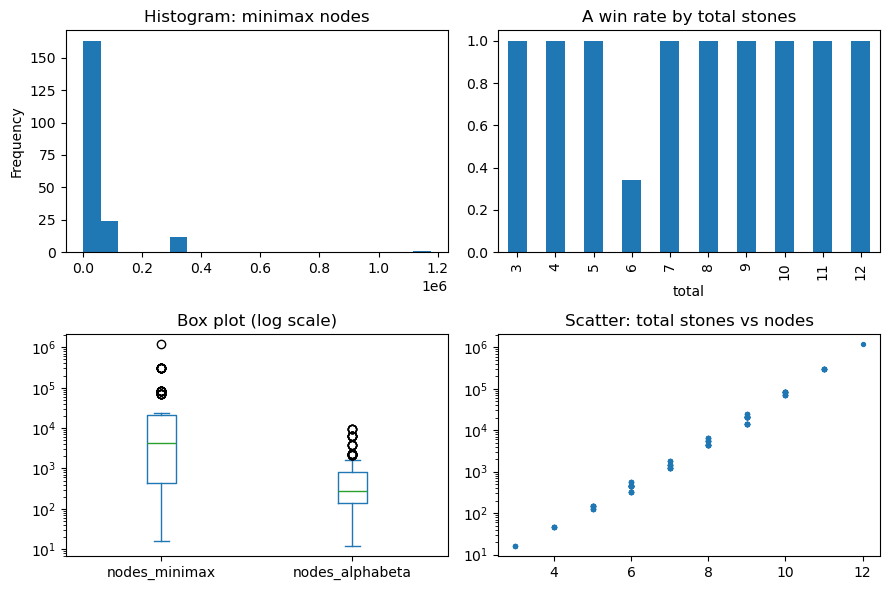

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
df["nodes_minimax"].plot(kind="hist", bins=20, ax=axes[0, 0], title="Histogram: minimax nodes")
df.groupby("total")["first_wins"].mean().plot(kind="bar", ax=axes[0, 1], title="A win rate by total stones")
df[["nodes_minimax", "nodes_alphabeta"]].plot(kind="box", logy=True, ax=axes[1, 0], title="Box plot (log scale)")
axes[1, 1].scatter(df["total"], df["nodes_minimax"], s=8)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Scatter: total stones vs nodes")
plt.tight_layout()
plt.show()

# Part 3: Motion output

## Cell 9: Animation of one game

This code creates an animated visualization of a complete Nim game using Matplotlib's `FuncAnimation`. It starts with the initial board `(3, 4, 5)` and simulates a game in which Player A uses the Minimax strategy to choose optimal moves, while Player B selects moves randomly. Each game state and move description is saved in the `history` list, including the number of stones removed and the selected pile. The `draw()` function updates the bar chart at each animation step to show the remaining stones in all three piles and display the current move. Once the game ends, the winner is displayed in the animation. Finally, `HTML(anim.to_jshtml())` converts the animation into an interactive HTML output that can be viewed directly inside the Jupyter Notebook.

In [23]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

rng = np.random.default_rng(1)
board, player = START, "A"
history = [(board, "start")]
while sum(board) > 0:
    old = board
    if player == "A":
        board = best_move(board, "A")
    else:
        options = moves(board)
        board = options[rng.integers(len(options))]
    i = [k for k in range(3) if board[k] != old[k]][0]
    history.append((board, f"{player} takes {old[i] - board[i]} from pile {i}"))
    player = "B" if player == "A" else "A"
winner = "B" if player == "A" else "A"

fig, ax = plt.subplots(figsize=(4, 3), dpi=70)

def draw(t):
    piles, text = history[min(t, len(history) - 1)]
    ax.clear()
    ax.bar(["pile 0", "pile 1", "pile 2"], piles, color=["#4f46e5", "#ec4899", "#f59e0b"])
    ax.set_ylim(0, max(START) + 1)
    ax.set_title(text + ("   winner: " + winner if t >= len(history) - 1 else ""), fontsize=9)

anim = FuncAnimation(fig, draw, frames=len(history) + 3, interval=800)
plt.close(fig)
HTML(anim.to_jshtml())

## Cell 10: Interactive graphical Nim game (Human vs Minimax AI)

Run this cell in Jupyter. It draws the piles as stones and provides buttons so you can choose a pile and remove stones. The AI responds using `best_move`. Requires `ipywidgets` (install with `pip install ipywidgets` if needed).

This code creates an interactive Human-vs-AI Nim game using `ipywidgets` and Matplotlib inside a Jupyter Notebook. The human player can select a pile, choose how many stones to remove, and play against one of two AI strategies: Smart A (Minimax) or Smart B (Nim-sum). The `ai_turn()` function handles the AI's decisions according to the selected strategy, while the button callbacks manage player moves, validate inputs, update the game state, and detect the winner. The `draw_nim_board()` function visually displays the remaining stones in each pile, and the status area provides feedback about the current turn and game result. A reset button allows the user to start a new game at any time. Overall, this code provides a complete interactive interface for testing and comparing both intelligent strategies through direct gameplay.

In [24]:
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets

# Start a fresh human-vs-AI game.
game_state = {"board": START, "player": "Human", "over": False}

pile_picker = widgets.Dropdown(
    options=[("Pile 1", 0), ("Pile 2", 1), ("Pile 3", 2)],
    value=0, description="Choose pile:"
)
take_picker = widgets.Dropdown(
    options=[("1 stone", 1)], value=1, description="Remove:"
)
strategy_picker = widgets.Dropdown(options=["Smart A (Minimax)", "Smart B (Nim-sum)"],
                                    value="Smart A (Minimax)", description="AI:")
take_button = widgets.Button(description="Take stones", button_style="success")
reset_button = widgets.Button(description="New game", button_style="")
status = widgets.HTML()
game_output = widgets.Output()

def refresh_take_options(*args):
    board = game_state["board"]
    pile_index = pile_picker.value
    available = board[pile_index]
    options = [(f"{n} stone" if n == 1 else f"{n} stones", n)
               for n in range(1, available + 1)]
    take_picker.options = options
    if options:
        take_picker.value = options[0][1]
    take_button.disabled = (game_state["over"] or available == 0)

def draw_nim_board():
    board = game_state["board"]
    with game_output:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(7, 3))
        colors = ["#4f46e5", "#ec4899", "#f59e0b"]
        for i, count in enumerate(board):
            if count:
                ax.scatter([i] * count, list(range(1, count + 1)),
                           s=650, color=colors[i], edgecolor="white", linewidth=1.5)
            ax.text(i, 0, f"Pile {i+1}: {count}", ha="center", va="top",
                    fontsize=11, fontweight="bold")
        ax.set_xlim(-0.6, 2.6)
        ax.set_ylim(-0.8, max(START) + 1.2)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"Nim — Human vs {strategy_picker.value}", fontsize=14)
        for spine in ax.spines.values():
            spine.set_visible(False)
        plt.show()
        plt.close(fig)

def update_status(message=None):
    if message:
        status.value = f"<b>{message}</b>"
    elif game_state["over"]:
        status.value = "<b>Game over.</b>"
    else:
        status.value = "<b>Your turn:</b> choose a non-empty pile and how many stones to remove."

def ai_turn():
    board = game_state["board"]
    if sum(board) == 0:
        game_state["over"] = True
        return "You took the last stone. You win!"
    next_board = (best_move(board, "B") if strategy_picker.value.startswith("Smart A")
                  else smart_b_move(board))
    game_state["board"] = next_board
    if sum(next_board) == 0:
        game_state["over"] = True
        return "The AI took the last stone. AI wins."
    return "AI made its move. Your turn."

def on_take_clicked(_):
    if game_state["over"]:
        return
    board = list(game_state["board"])
    pile_index, amount = pile_picker.value, take_picker.value
    if board[pile_index] < amount or amount < 1:
        update_status("Invalid move — choose a non-empty pile.")
        return
    board[pile_index] -= amount
    game_state["board"] = tuple(board)
    if sum(board) == 0:
        game_state["over"] = True
        message = "You took the last stone. You win!"
    else:
        message = ai_turn()
    refresh_take_options()
    draw_nim_board()
    update_status(message)
    take_button.disabled = game_state["over"]

def on_reset_clicked(_):
    game_state.update({"board": START, "player": "Human", "over": False})
    refresh_take_options()
    draw_nim_board()
    update_status("New game started. Your turn.")
    take_button.disabled = False

pile_picker.observe(refresh_take_options, names="value")
take_button.on_click(on_take_clicked)
reset_button.on_click(on_reset_clicked)

refresh_take_options()
draw_nim_board()
update_status()
display(widgets.VBox([
    widgets.HBox([strategy_picker, pile_picker, take_picker, take_button, reset_button]),
    status,
    game_output
]))

## Challenges 
Implemented: Smart B alongside Smart A.
Remaining extensions: 4 piles, other pile ranges, ordering by Nim-sum, and normal versus misere rule.